# Laos in EM-DAT, with detection

What does the event likelihood with population-dependent detection, the fastest model in 11 that corrects for where people live, say about where climate-related events start in Laos?

The record is EM-DAT's hydrometeorological and climatological events in Laos from 1990 to 2023, placed on GADM units by EM-DAT's own coding where it has one and by Geo-Disasters' footprints otherwise. An event with neither is recorded at the country level. The model is 11's: a log rate of event centers per atom from a covariate, an HSGP field and nested ADM1 and ADM2 offsets, a level each event is reported at, and a detection probability that rises with the population of the unit it is reported in. In 11 this model recovered the shape of the rate and of detection but not their levels, which it cannot separate, so the totals below are set by the prior on detection.

In [1]:
from pathlib import Path

import arviz as az
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import pymc as pm
import pytensor.tensor as pt
import xarray as xr

from arviz_plots import PlotCollection

from climate_risk.data.gadm import load_units_in_country
from climate_risk.data.geo_disasters import load_resolved_units
from climate_risk.data.ghsl import population_on_cells
from climate_risk.data_functions.emdat_processing import DISASTER_CLASSES, event_geography, load_emdat_events
from climate_risk.data_functions.rivers_data_loader import load_rivers_data
from climate_risk.geo.crs import PROJECTED_CRS, to_km
from climate_risk.geo.distance import get_distance_to
from climate_risk.geo.raster import assign_cells_to_units, build_cell_grid, dissolve_place_boundary
from climate_risk.models.aggregation import Aggregation
from climate_risk.plotting import configure_plot_style

configure_plot_style()

CACHE_DIR = Path("../../data")
ISO = "LAO"
SEED = 20261022

## Geography

Atoms are the cells of a 10 km lattice over Laos. Each atom belongs to the ADM1 and ADM2 unit covering most of it.

In [2]:
RESOLUTION_KM = 10.0
LEVELS = ("ADM2", "ADM1", "ADM0")

units = {
    "ADM2": load_units_in_country(ISO, 2, CACHE_DIR),
    "ADM1": load_units_in_country(ISO, 1, CACHE_DIR),
}
boundary = dissolve_place_boundary(units["ADM1"][["geometry"]], iso3=ISO)
units["ADM0"] = gpd.GeoDataFrame({"gid": [ISO], "name": ["Laos"], "admin_level": [0]}, geometry=boundary.geometry.to_numpy(), crs=boundary.crs)
grid = build_cell_grid(boundary, resolution_km=RESOLUTION_KM)
atoms = grid.cells.reset_index(drop=True)
n_atoms = len(atoms)
column_of_cell = pd.Series(np.arange(n_atoms), index=atoms["cell_id"].to_numpy())

# Every (atom, unit) pair that overlaps, with units as positions into units[level].
overlaps = {}
for level in LEVELS:
    pairs = assign_cells_to_units(grid, units[level])
    position = pd.Series(np.arange(len(units[level])), index=units[level]["gid"].to_numpy())
    overlaps[level] = pd.DataFrame({"atom": column_of_cell.loc[pairs["cell_id"]].to_numpy(),
                                    "unit": position.loc[pairs["gid"]].to_numpy(),
                                    "coverage": pairs["coverage"].to_numpy()})

# The unit covering most of each atom, which is the unit an event centered there is reported in.
unit_of_atom = {level: overlaps[level].sort_values("coverage", ascending=False).drop_duplicates("atom").set_index("atom")["unit"].reindex(np.arange(n_atoms)).to_numpy()
                for level in LEVELS}
n_units = {level: len(units[level]) for level in LEVELS}
unit_offset = dict(zip(LEVELS, np.cumsum([0, *[n_units[level] for level in LEVELS[:-1]]]), strict=True))
n_all_units = sum(n_units.values())

pd.Series({
    "atoms": n_atoms,
    **{f"{level} units": n_units[level] for level in LEVELS},
    **{f"{level} units dominating no atom": n_units[level] - len(np.unique(unit_of_atom[level])) for level in LEVELS},
})

atoms                            2606
ADM2 units                        142
ADM1 units                         18
ADM0 units                          1
ADM2 units dominating no atom       1
ADM1 units dominating no atom       0
ADM0 units dominating no atom       0
dtype: int64

## Covariate and population

The hazard covariate is the log distance from each atom to the nearest major river in HydroRIVERS, standardized. The library has no elevation source, so 11's second covariate is absent. Population is GHS-POP for 2005, the middle of the record, summed onto atoms. Each unit's detection covariate is its log population standardized across the units of its level, as in 11. Laos is one ADM0 unit, so its value is zero.

In [3]:
POPULATION_EPOCH = 2005
COVARIATE_NAMES = ("log distance to river",)


def standardized(values):
    """Values shifted to mean zero and scaled to unit standard deviation."""
    return (values - values.mean()) / values.std()


rivers = load_rivers_data(CACHE_DIR)
river_km = to_km(get_distance_to(rivers.cx[boundary.total_bounds[0] - 1:boundary.total_bounds[2] + 1, boundary.total_bounds[1] - 1:boundary.total_bounds[3] + 1], atoms)["distance_to_closest"].to_numpy())
covariates = standardized(np.log(river_km + 1.0))[:, None]

population = population_on_cells(grid, POPULATION_EPOCH, CACHE_DIR)
unit_population = {level: np.bincount(unit_of_atom[level], weights=population, minlength=n_units[level]) for level in LEVELS}
population_z = np.concatenate([
    standardized(np.log(np.maximum(unit_population[level], 1.0))) if n_units[level] > 1 else np.zeros(1)
    for level in LEVELS
])

# Projected atom centers, scaled so the longer side of Laos spans one unit, the domain 11's lengthscale prior assumes.
projected = atoms.to_crs(PROJECTED_CRS).geometry
atom_xy = np.column_stack([projected.x, projected.y])
DOMAIN_KM = to_km(np.ptp(atom_xy, axis=0).max())
atom_centroids = (atom_xy - atom_xy.min(axis=0)) / np.ptp(atom_xy, axis=0).max()

pd.Series({
    "river distance, median km": np.median(river_km),
    "river distance, max km": river_km.max(),
    "population, millions": population.sum() / 1e6,
    "correlation of log population density with river covariate": np.corrcoef(np.log1p(population / atoms["place_area_km2"]), covariates[:, 0])[0, 1],
    "domain side, km": DOMAIN_KM,
}).round(2)

river distance, median km                                     24.10
river distance, max km                                       106.51
population, millions                                           5.89
correlation of log population density with river covariate    -0.30
domain side, km                                              991.32
dtype: float64

## The record

Each event names a set of units. EM-DAT's GADM coding comes first and Geo-Disasters adds units only for ground EM-DAT leaves unnamed, which is the order `event_geography` applies. An event naming units at both ADM1 and ADM2 is reported at the coarser level, and its union is every atom any named unit overlaps. An event naming nothing, with or without a coordinate, is reported at ADM0.

In [4]:
FIRST_YEAR, LAST_YEAR = 1990, 2023
LEVEL_OF_ADMIN = {2: "ADM2", 1: "ADM1"}

events = load_emdat_events(CACHE_DIR).filter(
    (pl.col("ISO") == ISO)
    & pl.col("Disaster Type").is_in(list(DISASTER_CLASSES))
    & pl.col("date").dt.year().is_between(FIRST_YEAR, LAST_YEAR)
)
resolved = pl.from_pandas(load_resolved_units([ISO], CACHE_DIR)).select(
    pl.col("DisNo."),
    pl.col("gid"),
    pl.col("name"),
    pl.col("admin_level").cast(pl.Int8),
    pl.col("geocoding_q").cast(pl.Int8),
    pl.col("overlap"),
)
geography = event_geography(events, resolved=resolved)

position = {level: pd.Series(np.arange(n_units[level]), index=units[level]["gid"].to_numpy()) for level in ("ADM2", "ADM1")}


def named_units(rows):
    """The units an event names, as positions into units[level], keyed by level."""
    named = {}
    for admin, gid in rows.filter(pl.col("gid").is_not_null()).select("admin_level", "gid").iter_rows():
        level = LEVEL_OF_ADMIN[admin]
        named.setdefault(level, set()).add(int(position[level].loc[gid]))

    return {level: tuple(sorted(found)) for level, found in named.items()}


def provinces_of(named):
    """Positions of the provinces an event names, directly or through a district, empty when it names neither."""
    districts = overlaps["ADM2"]["unit"].isin(named.get("ADM2", ()))

    return frozenset(named.get("ADM1", ())) | frozenset(unit_of_atom["ADM1"][overlaps["ADM2"]["atom"][districts]].tolist())


event_rows = []
for (disno,), rows in geography.group_by("DisNo.", maintain_order=True):
    named = named_units(rows)
    event_rows.append({
        "DisNo.": disno,
        "level": "ADM1" if "ADM1" in named else "ADM2" if named else "ADM0",
        "named": named or {"ADM0": (0,)},
        "provinces": provinces_of(named),
        "source": "+".join(sorted(set(rows["geometry_source"]))),
    })

record = pd.DataFrame(event_rows).merge(events.select("DisNo.", "Disaster Type", pl.col("date").dt.year().alias("year")).to_pandas(), on="DisNo.")

pd.concat([
    record.groupby("level").size().rename("events"),
    record.groupby(["level", "source"]).size().unstack(fill_value=0),
], axis=1)

,events,country,gadm,geo_disasters
level,,,,
ADM0,9,9,0,0
ADM1,22,0,18,4
ADM2,5,0,5,0


36 events: 23 floods, 11 storms and 2 droughts. 22 are reported at ADM1, naming a median of 4.5 provinces, 5 at ADM2, and 9 name nothing below the country. Seven name units at both ADM1 and ADM2.

## The model

11's event likelihood with detection, on the real geography. An event centered at atom $c$ is reported at level $L$ with probability $\pi_L$ and enters the record with the detection probability of $c$'s unit at that level, $q_{u_L(c)} = \operatorname{logit}^{-1}(\alpha + \beta z_{u_L(c)})$. Events sharing a record are grouped, so the likelihood is a Poisson count of recorded events and, for each distinct record, the share of recorded intensity whose center falls in the record's union at the record's level. Laos has one ADM0 unit, so there is no ADM0 offset and the intercept carries the country's level.

Simulated-data recovery for this model is 11's, on a lattice of the same size and a record of comparable length. It is not repeated here.

In [5]:
HSGP_BOUNDARY_FACTOR = 4.0
HSGP_BASIS_PER_AXIS = 50
OFFSET_SD_PRIOR = 0.5
OFFSET_LEVELS = ("ADM2", "ADM1")
# A prior guess at the event centers over the whole record, recorded or not, which fixes where the intercept sits.
PRIOR_EVENT_CENTERS = 100
sample_kwargs = {
    "chains": 8,
    "cores": 8,
    "tune": 500,
    "draws": 250,
    "target_accept": 0.9,
    "nuts_sampler": "nutpie",
    "random_seed": SEED,
}

# Each (level, atom) in one flat index, level-major, and the all-units index of the atom's unit at that level.
center_unit = np.concatenate([unit_offset[level] + unit_of_atom[level] for level in LEVELS])


def union_cells(named):
    """The (level, atom) cells of an event's union, read at the level it is reported at."""
    level = "ADM1" if "ADM1" in named else next(iter(named))
    atoms_named = np.unique(np.concatenate([overlaps[at]["atom"][overlaps[at]["unit"].isin(found)].to_numpy() for at, found in named.items()]))

    return LEVELS.index(level), LEVELS.index(level) * n_atoms + atoms_named


record_key = record["named"].map(lambda named: tuple(sorted(named.items())))
distinct = record.assign(key=record_key).groupby("key", sort=False).agg(multiplicity=("DisNo.", "size"), named=("named", "first"))
cells_by_record = [union_cells(named) for named in distinct["named"]]
detection_terms = {
    "multiplicity": distinct["multiplicity"].to_numpy(),
    "union": Aggregation(units=tuple(f"record {index}" for index in range(len(distinct))),
                         rows=np.repeat(np.arange(len(distinct)), [len(cells) for _, cells in cells_by_record]),
                         columns=np.concatenate([cells for _, cells in cells_by_record]),
                         weights=np.ones(sum(len(cells) for _, cells in cells_by_record)),
                         n_cells=len(LEVELS) * n_atoms),
}
COORDS = {
    "covariate": list(COVARIATE_NAMES),
    "atom": np.arange(n_atoms),
    "unit": np.arange(n_all_units),
    "level": list(LEVELS),
    "record": detection_terms["union"].units,
    **{level: units[level]["gid"].to_list() for level in OFFSET_LEVELS},
}


def latent_log_rate():
    """The log rate of event centers at every atom, built inside the current model."""
    intercept = pm.Normal("intercept",
                          mu=np.log(PRIOR_EVENT_CENTERS / n_atoms),
                          sigma=1.0)
    slopes = pm.Normal("slopes",
                       mu=0.0,
                       sigma=1.0,
                       dims="covariate")

    # Mode at 0.1 of the domain, about 100 km, with a tail out past the width of the country.
    field_lengthscale = pm.InverseGamma("field_lengthscale",
                                        alpha=3.0,
                                        beta=0.4)
    field_amplitude = pm.HalfNormal("field_amplitude", sigma=1.0)
    gp = pm.gp.HSGP(m=[HSGP_BASIS_PER_AXIS, HSGP_BASIS_PER_AXIS],
                    c=HSGP_BOUNDARY_FACTOR,
                    cov_func=field_amplitude**2 * pm.gp.cov.Matern32(input_dim=2, ls=field_lengthscale))
    field = gp.prior("field", X=atom_centroids, dims="atom")

    offset_part = 0.0
    for level in OFFSET_LEVELS:
        offset_sd = pm.HalfNormal(f"{level}_offset_sd", sigma=OFFSET_SD_PRIOR)
        standard = pm.Normal(f"{level}_offset_standard",
                             mu=0.0,
                             sigma=1.0,
                             dims=level)
        offsets = pm.Deterministic(f"{level}_offset", offset_sd * standard, dims=level)
        offset_part = offset_part + offsets[unit_of_atom[level]]

    return pm.Deterministic("log_rate",
                            intercept + pm.math.dot(covariates, slopes) + field + offset_part,
                            dims="atom")


def recorded_intensity():
    """Recorded events per (level, atom): centers, times the level's share, times detection by the center's unit there."""
    rate = pm.math.exp(latent_log_rate())
    naming_intercept = pm.Normal("naming_intercept",
                                 mu=0.0,
                                 sigma=1.5)
    naming_slope = pm.Normal("naming_slope",
                             mu=0.0,
                             sigma=1.0)
    naming = pm.Deterministic("naming_probability",
                              pm.math.invlogit(naming_intercept + naming_slope * population_z),
                              dims="unit")
    level_probability = pm.Dirichlet("level_probability",
                                     a=np.ones(len(LEVELS)),
                                     dims="level")

    return level_probability[:, None] * rate[None, :] * naming[center_unit].reshape((len(LEVELS), n_atoms))


def counted_logp(count, probability):
    """Log probability of ``count`` events sharing one record, given the record's probability under the model."""
    return count * pt.log(probability)


def build_event_detection_model():
    """The event likelihood with each event recorded with the detection probability of its center's unit."""
    terms = detection_terms

    with pm.Model(coords=COORDS) as model:
        recorded = recorded_intensity()
        recorded_rate = pm.Deterministic("recorded_rate", recorded.sum())

        pm.Poisson("event_count",
                   mu=recorded_rate,
                   observed=terms["multiplicity"].sum())
        pm.CustomDist("record_count",
                      terms["union"].aggregate_symbolic(recorded.ravel()) / recorded_rate,
                      logp=counted_logp,
                      observed=terms["multiplicity"],
                      dims="record")

    return model


event_detection_model = build_event_detection_model()

pd.Series({
    "distinct records": len(distinct),
    "largest union, atoms": int(np.bincount(detection_terms["union"].rows).max()),
    "free parameters": sum(value.size for value in event_detection_model.initial_point().values()),
})

distinct records          28
largest union, atoms    2606
free parameters         2670
dtype: int64

## Prior predictive

How many recorded events over 34 years, and how many event centers recorded or not, the priors allow before seeing the record.

Sampling: [ADM1_offset_sd, ADM1_offset_standard, ADM2_offset_sd, ADM2_offset_standard, event_count, field_amplitude, field_hsgp_coeffs, field_lengthscale, intercept, level_probability, naming_intercept, naming_slope, slopes]


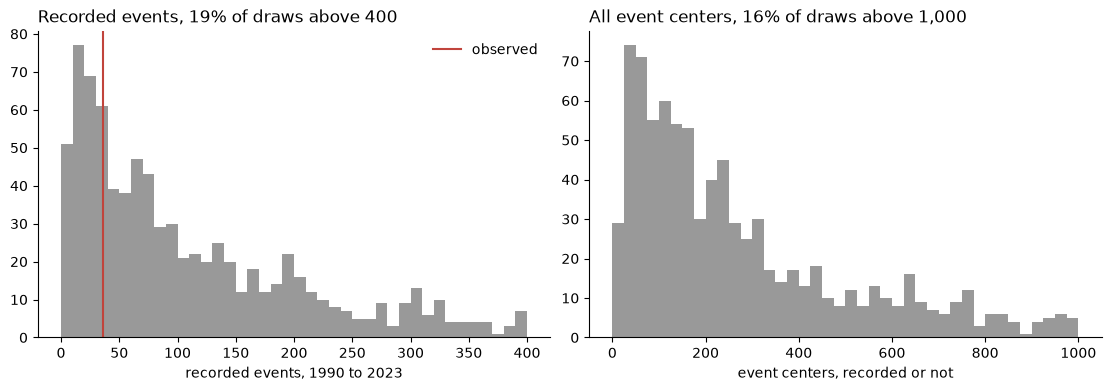

recorded events, prior median                       107.50
recorded events, prior 90% interval          (9.0, 1226.0)
share of draws within a factor of 3 of 36             0.44
dtype: object

In [6]:
PRIOR_DRAWS = 1_000

with event_detection_model:
    prior = pm.sample_prior_predictive(draws=PRIOR_DRAWS,
                                       var_names=["recorded_rate", "log_rate", "naming_probability", "event_count"],
                                       random_seed=SEED)

prior_total = np.exp(prior.prior["log_rate"]).sum("atom").to_numpy().ravel()
prior_recorded = prior.prior_predictive["event_count"].to_numpy().ravel()

figure, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(prior_recorded[prior_recorded <= 400],
             bins=np.arange(0, 401, 10),
             color="0.6")
axes[0].axvline(detection_terms["multiplicity"].sum(),
                color="#c1443c",
                label="observed")
axes[0].set_xlabel("recorded events, 1990 to 2023")
axes[0].set_title(f"Recorded events, {np.mean(prior_recorded > 400):.0%} of draws above 400", loc="left")
axes[0].legend(frameon=False)
axes[1].hist(prior_total[prior_total <= 1_000],
             bins=np.arange(0, 1_001, 25),
             color="0.6")
axes[1].set_xlabel("event centers, recorded or not")
axes[1].set_title(f"All event centers, {np.mean(prior_total > 1_000):.0%} of draws above 1,000", loc="left")
plt.show()

pd.Series({
    "recorded events, prior median": np.median(prior_recorded),
    "recorded events, prior 90% interval": tuple(np.quantile(prior_recorded, [0.05, 0.95]).round(0)),
    "share of draws within a factor of 3 of 36": np.mean((prior_recorded >= 12) & (prior_recorded <= 108)),
})

## Fit

In [7]:
with event_detection_model:
    fit = pm.sample(**sample_kwargs)

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, naming_intercept, naming_slope, level_probability]


Output()

In [8]:
SUMMARY_VARIABLES = ["intercept", "slopes", "field_amplitude", "field_lengthscale", "ADM2_offset_sd", "ADM1_offset_sd", "naming_intercept", "naming_slope", "level_probability", "recorded_rate"]
every_free = az.summary(fit, var_names=[variable.name for variable in event_detection_model.free_RVs])

pd.concat([
    az.summary(fit, var_names=SUMMARY_VARIABLES),
    pd.DataFrame({"r_hat": [every_free["r_hat"].max()], "ess_bulk": [every_free["ess_bulk"].min()]}, index=["worst over every free parameter"]),
    pd.DataFrame({"mean": [int(fit.sample_stats["diverging"].sum())]}, index=["divergences"]),
]).round(2)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,-4.09,0.87,-5.43,-2.66,210.09,416.84,1.05,0.06,0.03
slopes[log distance to river],-1.01,0.51,-1.76,-0.13,310.35,350.03,1.02,0.03,0.02
field_amplitude,0.97,0.57,0.17,2.00,300.82,356.94,1.02,0.03,0.01
field_lengthscale,0.18,0.16,0.06,0.43,789.66,813.93,1.01,0.01,0.02
ADM2_offset_sd,0.44,0.34,0.04,1.07,375.21,263.99,1.02,0.01,0.01
ADM1_offset_sd,0.41,0.31,0.03,0.99,402.75,359.31,1.01,0.01,0.01
naming_intercept,-1.26,1.37,-3.12,1.08,254.07,286.47,1.03,0.09,0.08
naming_slope,0.62,0.71,-0.47,1.75,926.00,807.45,1.01,0.02,0.02
level_probability[ADM2],0.16,0.06,0.07,0.26,1697.05,1449.58,1.00,0.00,0.00
level_probability[ADM1],0.55,0.10,0.39,0.69,945.40,1088.62,1.01,0.00,0.00


## Posterior against prior

What the record moved and what it left at the prior. Event centers are the total over Laos and the whole record, recorded or not.

Sampling: [ADM1_offset_sd, ADM2_offset_sd, field_amplitude, field_lengthscale, intercept, level_probability, naming_intercept, naming_slope, slopes]


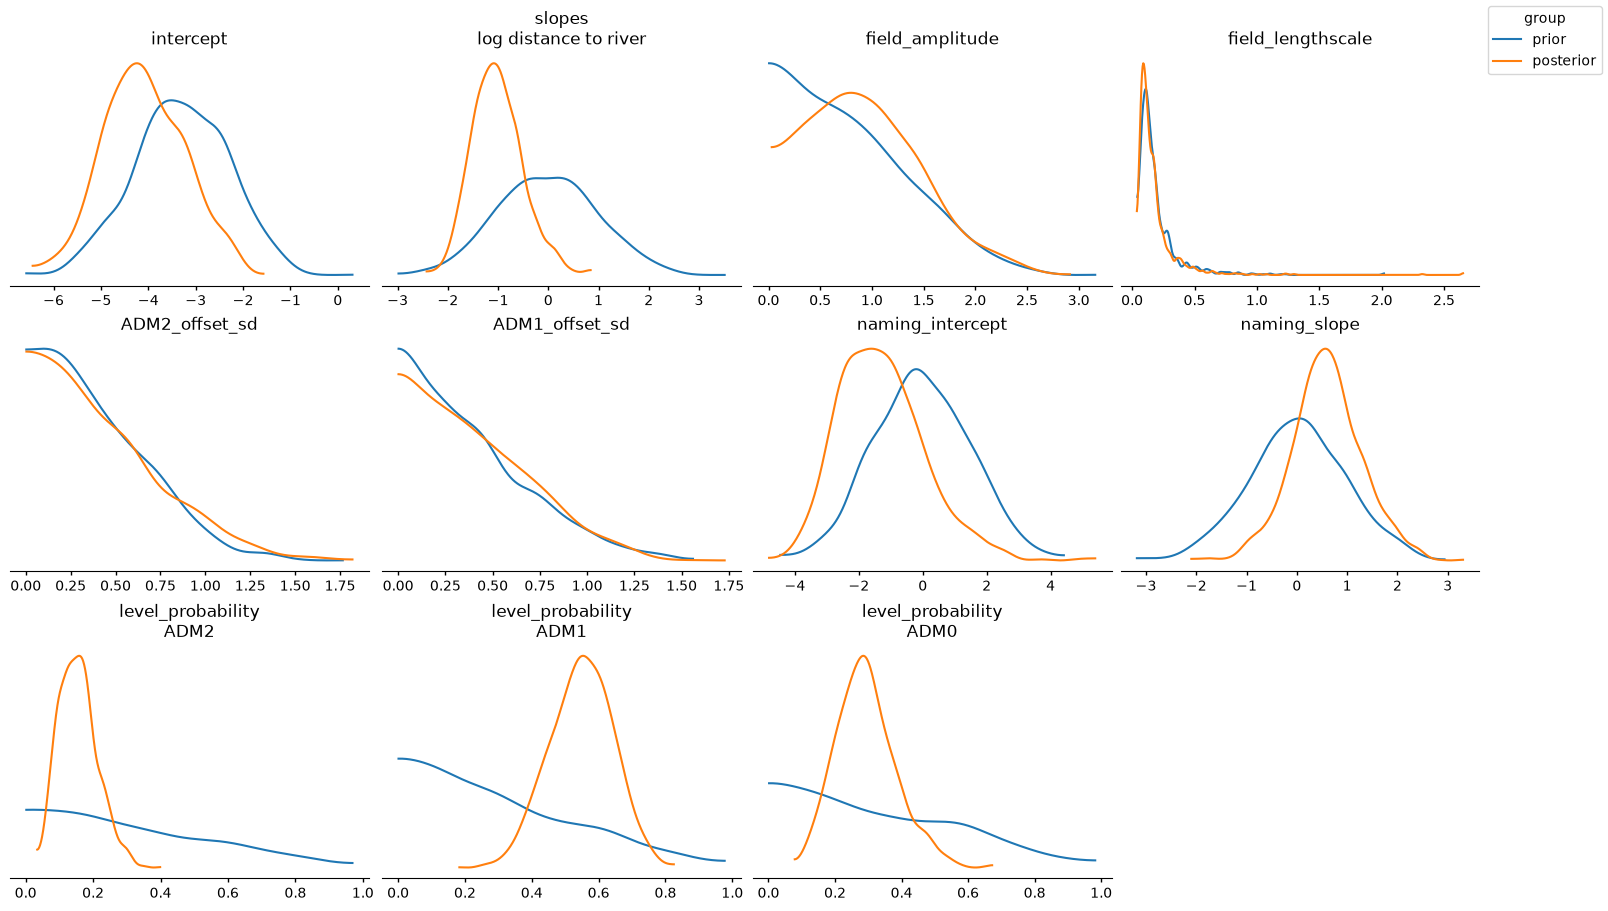

In [9]:
PARAMETERS = ["intercept", "slopes", "field_amplitude", "field_lengthscale", "ADM2_offset_sd", "ADM1_offset_sd", "naming_intercept", "naming_slope", "level_probability"]

with event_detection_model:
    fit["prior"] = pm.sample_prior_predictive(draws=PRIOR_DRAWS, 
                                              var_names=PARAMETERS, 
                                              random_seed=SEED)["prior"]

az.plot_prior_posterior(fit,
                        var_names=PARAMETERS,
                        col_wrap=4,
                        figure_kwargs={"figsize": (16, 9)})
plt.show()

posterior = fit.posterior
YEARS = LAST_YEAR - FIRST_YEAR + 1
adm2_units = slice(unit_offset["ADM2"], unit_offset["ADM2"] + n_units["ADM2"])

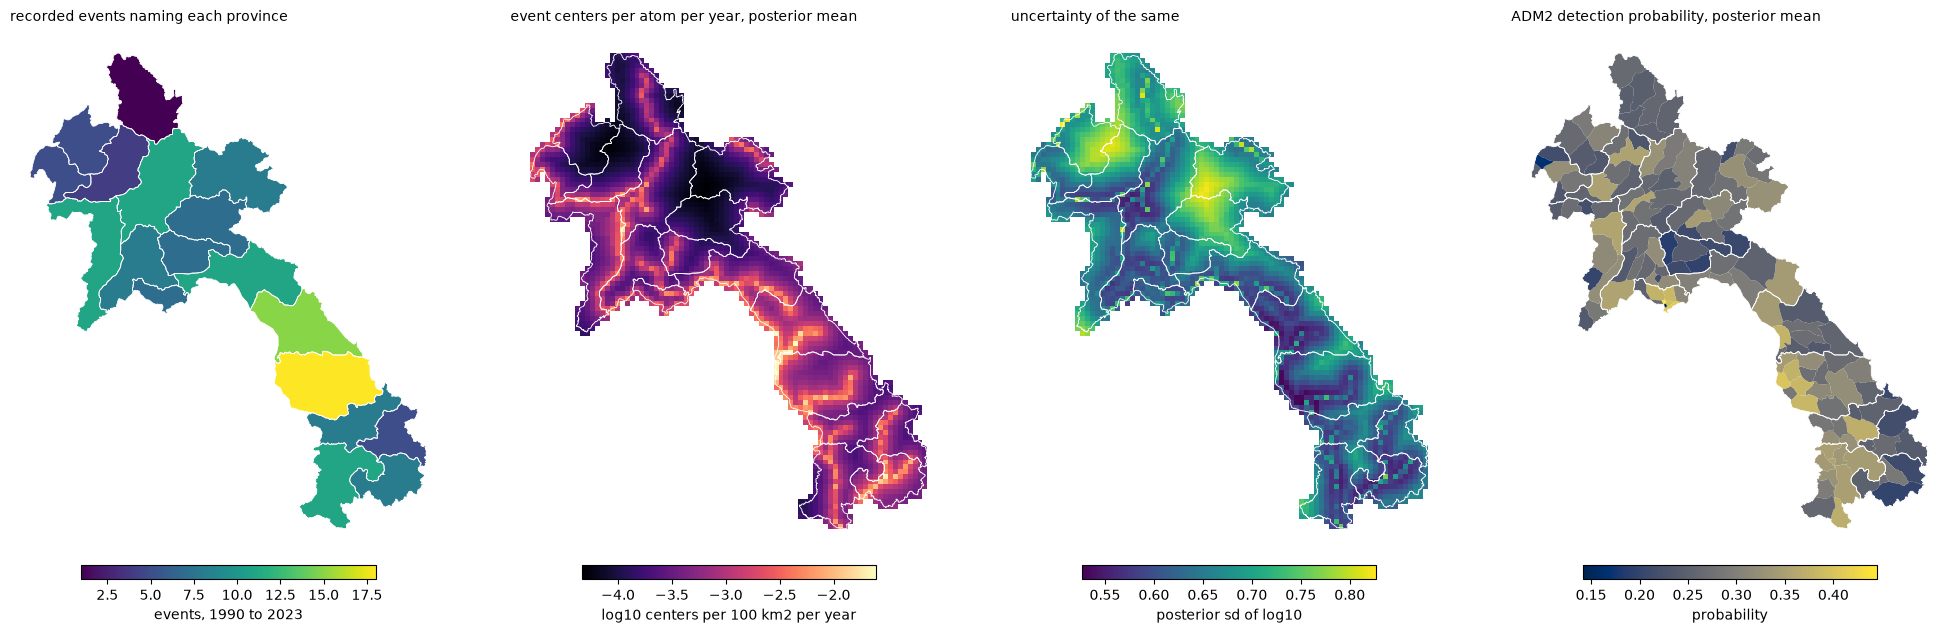

In [10]:
atom_cells = gpd.GeoDataFrame(geometry=grid.footprints.reset_index(drop=True), crs=grid.footprints.crs)
adm1_borders = units["ADM1"].boundary

log10_annual = (posterior["log_rate"] - np.log(YEARS)) / np.log(10)
events_naming = np.bincount([province for found in record["provinces"] for province in found], minlength=n_units["ADM1"])

panels = {
    "recorded events naming each province": (units["ADM1"].assign(value=events_naming), "viridis", "events, 1990 to 2023"),
    "event centers per atom per year, posterior mean": (atom_cells.assign(value=log10_annual.mean(("chain", "draw")).to_numpy()), "magma", "log10 centers per 100 km2 per year"),
    "uncertainty of the same": (atom_cells.assign(value=log10_annual.std(("chain", "draw")).to_numpy()), "viridis", "posterior sd of log10"),
    "ADM2 detection probability, posterior mean": (units["ADM2"].assign(value=posterior["naming_probability"].isel(unit=adm2_units).mean(("chain", "draw")).to_numpy()), "cividis", "probability"),
}

figure, axes = plt.subplots(1, len(panels), figsize=(5.0 * len(panels), 6.2))
for axis, (title, (frame, cmap, label)) in zip(axes, panels.items(), strict=True):
    frame.plot(column="value",
               ax=axis,
               cmap=cmap,
               legend=True,
               legend_kwds={"label": label, "shrink": 0.6, "location": "bottom", "pad": 0.02})
    adm1_borders.plot(ax=axis,
                      color="white",
                      linewidth=0.6)
    axis.set_axis_off()
    axis.set_title(title, loc="left", fontsize=10)
plt.show()

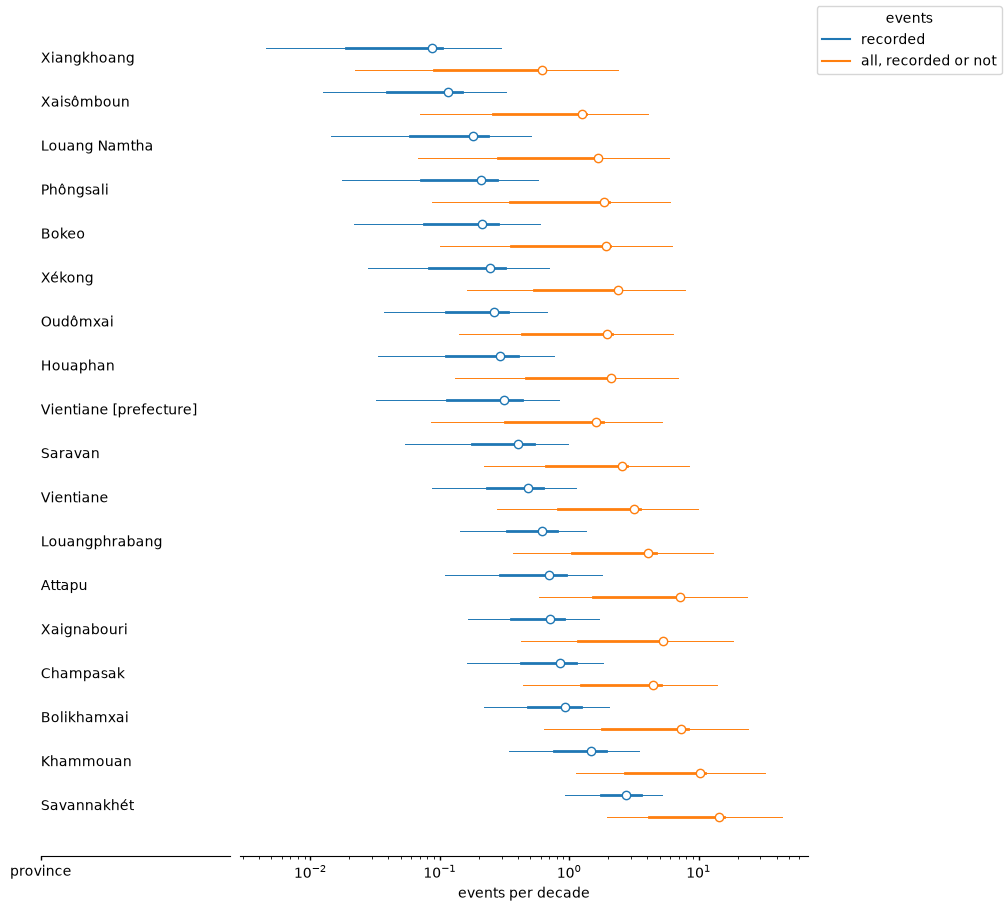

In [11]:
DECADE = 10

province_of_atom = xr.DataArray(units["ADM1"]["name"].to_numpy()[unit_of_atom["ADM1"]], dims="atom", name="province")
rate = np.exp(posterior["log_rate"])
detection = (posterior["level_probability"]
             * posterior["naming_probability"].isel(unit=xr.DataArray(center_unit.reshape(len(LEVELS), n_atoms), dims=("level", "atom")))).sum("level")

per_decade = xr.concat([(rate * detection).groupby(province_of_atom).sum(),
                        rate.groupby(province_of_atom).sum()],
                       dim=pd.Index(["recorded", "all, recorded or not"], name="events")) * DECADE / YEARS
per_decade = per_decade.sortby(per_decade.sel(events="recorded").mean(("chain", "draw")))

forest = az.plot_forest(per_decade.to_dataset(name="events per decade"),
                        combined=True,
                        labels=["province"],
                        aes={"color": ["events"]},
                        figure_kwargs={"figsize": (10, 9)})
forest.add_legend("events")
# Recorded and total events differ by an order of magnitude, so both are read on a log scale.
interval_axis = forest.viz["figure"].item().axes[-1]
interval_axis.set_xscale("log")
interval_axis.set_xlabel("events per decade")
plt.show()

The two bars answer different questions with different support from the record. Recorded events per decade are what the record constrains: their province medians sum to 9, near the 10.6 a decade the record holds, and their 89% intervals span 1.2 orders of magnitude on average, 0.8 for Savannakhet. All events, recorded or not, divide the recorded rate by a detection probability whose level comes from the prior, so their intervals span 1.7 orders of magnitude on average and their province medians sum to 38 a decade, a number the record does not fix.

The ranking is the same under both. Savannakhet leads at a median of 2.6 recorded and 8 total events a decade, followed by Khammouan, Bolikhamxai, Champasak and Attapu along the Mekong in the center and south, and Xiangkhoang is last at 0.05 and 0.24. The gap between the bars is the inverse of detection, and it varies with population: the median ratio of total to recorded events is 3.2 in Savannakhet, 3.4 in Vientiane prefecture and 3.6 in Champasak, the most populous provinces, and 7 to 8 in Attapu, Xekong and Xaisomboun. That variation comes from the naming slope, whose interval includes zero, so how much more of the sparse provinces' hazard goes unrecorded is the model's assumption more than the record's finding.

## Posterior predictive check

The record term cannot generate records: each event is observed as a set of units its center lies in, and nothing in the model chooses which set is written down. The check is a predictive model on the same `recorded_intensity` the fit uses, with recorded events counted by reporting level, by decade and by year, drawn with `sample_posterior_predictive`. The decade counts and the variance of annual counts test the stationary Poisson rate.

In [12]:
DECADES = {"1990s": (1990, 1999), "2000s": (2000, 2009), "2010 to 2023": (2010, 2023)}
decade_years = np.array([last - first + 1 for first, last in DECADES.values()])


def build_predictive_model():
    """The fitted model's recorded intensity, observed as counts by level, by decade and by year."""
    coords = COORDS | {"decade": list(DECADES), "year": np.arange(FIRST_YEAR, LAST_YEAR + 1)}
    with pm.Model(coords=coords) as model:
        recorded = recorded_intensity()
        pm.Poisson("level_count", mu=recorded.sum(axis=1), dims="level")
        pm.Poisson("decade_count", mu=recorded.sum() * decade_years / YEARS, dims="decade")
        pm.Poisson("annual_count", mu=recorded.sum() * pt.ones(YEARS) / YEARS, dims="year")

    return model


with build_predictive_model():
    ppc = pm.sample_posterior_predictive(fit,
                                         var_names=["level_count", "decade_count", "annual_count"],
                                         random_seed=SEED)

annual = record.groupby("year").size().reindex(ppc.posterior_predictive["year"].to_numpy(), fill_value=0)
ppc["observed_data"] = xr.Dataset({
    "level_count": ("level", record["level"].value_counts().reindex(LEVELS, fill_value=0).to_numpy()),
    "decade_count": ("decade", [annual.loc[first:last].sum() for first, last in DECADES.values()]),
    "annual_count": ("year", annual.to_numpy()),
}, coords=ppc.posterior_predictive.coords).drop_vars(["chain", "draw"])

Sampling: [annual_count, decade_count, level_count]


Output()

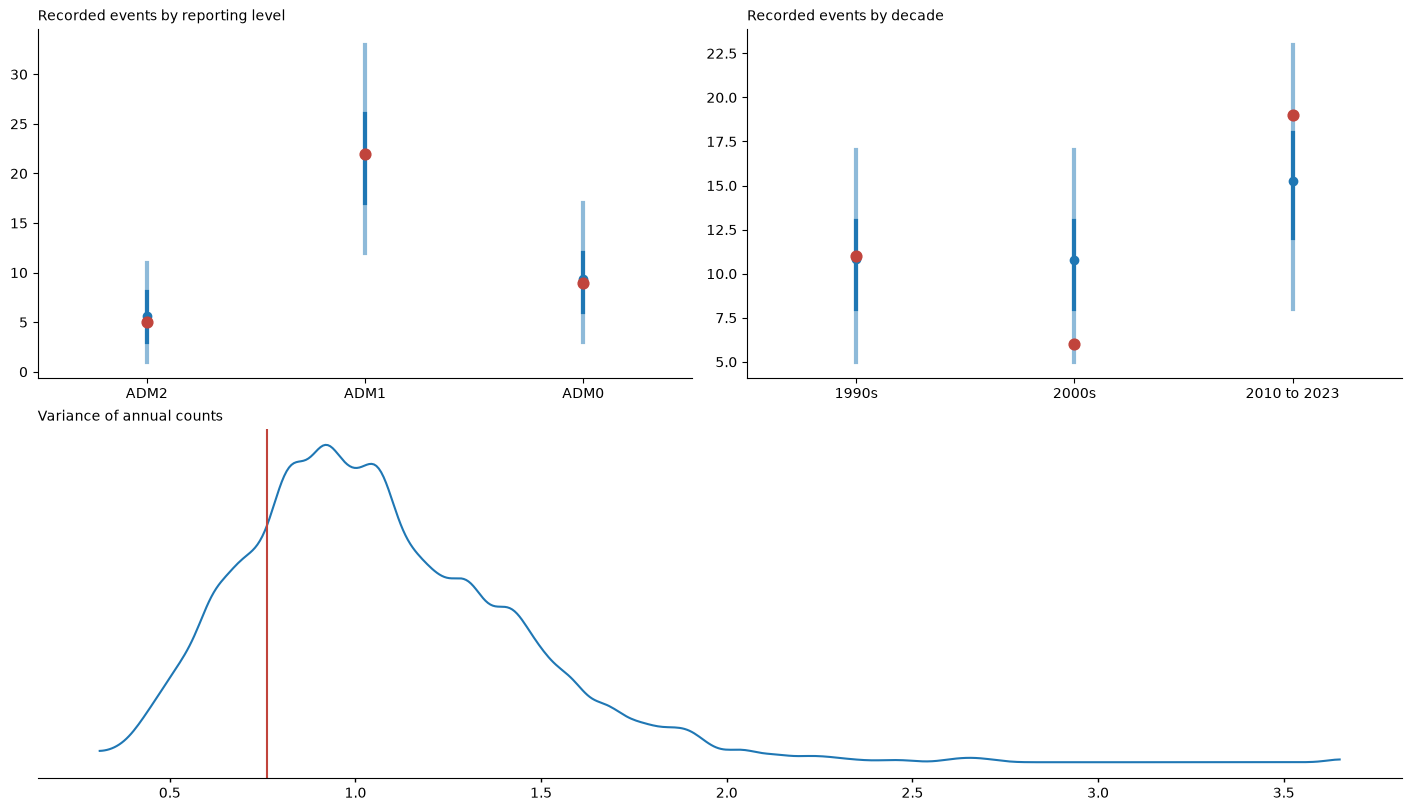

In [13]:
OBSERVED_COLOR = "#c1443c"


def plot_collection_on(axis, variable):
    """A PlotCollection drawing ``variable`` onto an existing axis, so ArviZ plots share one figure."""
    viz = xr.DataTree.from_dict({
        "/": xr.Dataset({"figure": np.array(axis.figure, dtype=object)}),
        "plot": xr.Dataset({variable: np.array(axis, dtype=object)}),
        "row_index": xr.Dataset({variable: 0}),
        "col_index": xr.Dataset({variable: 0}),
    })

    return PlotCollection(ppc.posterior_predictive.dataset[[variable]], viz, backend="matplotlib")


figure = plt.figure(figsize=(14, 8))
layout = figure.add_gridspec(2, 2)
level_axis = figure.add_subplot(layout[0, 0])
decade_axis = figure.add_subplot(layout[0, 1])
spread_axis = figure.add_subplot(layout[1, :])

for axis, variable in [(level_axis, "level_count"), (decade_axis, "decade_count")]:
    az.plot_ppc_interval(ppc,
                         var_names=[variable],
                         plot_collection=plot_collection_on(axis, variable),
                         visuals={"observed_markers": {"color": OBSERVED_COLOR, "marker": "o", "size": 60, "zorder": 4}})
az.plot_ppc_tstat(ppc,
                  var_names=["annual_count"],
                  t_stat="var",
                  plot_collection=plot_collection_on(spread_axis, "annual_count"),
                  visuals={"title": False, "observed_tstat": False})
spread_axis.axvline(float(ppc.observed_data["annual_count"].var()),
                    color=OBSERVED_COLOR)

for axis, coordinate, title in [(level_axis, "level", "Recorded events by reporting level"), (decade_axis, "decade", "Recorded events by decade")]:
    labels = ppc.observed_data[coordinate].to_numpy()
    axis.set_xticks(np.arange(len(labels)), labels)
    axis.set_xlim(-0.5, len(labels) - 0.5)
    axis.set_xlabel("")
    axis.set_ylabel("")
    axis.set_title(title, loc="left", fontsize=10)
spread_axis.set_title("Variance of annual counts", loc="left", fontsize=10)
plt.show()

Nothing here rejects the model, and little here could. The level counts sit in their intervals because the level probabilities are fitted to those counts. The 2000s' 6 events are low, with 13% of draws recording that few or fewer, and the variance of annual counts, 0.76, is at the 21st percentile of the draws, so there is no sign of the overdispersion a clustered or trending record would show. The record says which provinces an event names, not where it was centered, and most records name several, so there is no province count to check the spatial pattern against.

## What the fit says

The fit took 104 seconds with no divergences, a worst r_hat of 1.03 and a smallest bulk ESS of 283.

The record moved the river slope and left detection's level at the prior. The slope on log distance to a major river is -1.06 with a 90% interval from -1.86 to -0.20, against a prior centered at zero, so events start nearer the large rivers. In the posterior mean, 77% of event centers fall in the quarter of Laos within 10 km of a major river, which draws the river network on the rate map. The covariate's contribution to the log rate has 2.7 times the standard deviation of the field's posterior mean, so it sets most of the pattern within provinces. Savannakhet, which 18 of the 36 events name, holds 21% of the posterior rate, and Khammouan, Attapu and Bolikhamxai follow. The northern provinces and Xiangkhoang hold 1% to 3% each, and Phongsali, which one event names, holds 2%.

Two things limit what that pattern can claim. Most records name whole provinces or the country, so the river slope is learned from contrasts between unions and applied inside them. The concentration along rivers within a province is the covariate's extrapolation, not something the record shows. And detection is as 11 found it: the recorded total is pinned at 37 events (90% interval 27 to 48), while the total of all event centers is 276 with an interval from 47 to 814, because the naming intercept's posterior, -1.28 (-3.32 to 1.33), is about as wide as its prior. The record cannot tell a hazardous country with poor recording from a quiet one recorded well. The median ADM2 detection probability is 0.27 (0.04 to 0.79), and the naming slope, 0.54 (-0.54 to 1.65), leans toward populated districts being recorded more without excluding zero.

The event likelihood with detection fits a real country's record in under two minutes and returns atom-level center rates. Their relative pattern comes from the river covariate and the contrasts between provinces, and their level spans a factor of about 17. The posterior predictive check finds nothing wrong, but a record of 36 events named mostly at province level gives it little to test. A usable level needs an informative prior on how complete EM-DAT is for Laos, and a test of the spatial pattern needs either more events, from neighboring countries under a shared model, or finer footprints than EM-DAT's.